# DualTaskUNet — Pumpkin Leaf Segmentation & Severity Estimation
> **Thesis:** Localization, Segmentation & Severity Estimation of Pumpkin Leaf Diseases  
> **Architecture:** DualTaskUNet (Leaf + Lesion dual-head U-Net with Dice–Focal Loss)  
> **Dataset:** 100 pilot images (20/class × 5 classes) with automated pixel-level ground-truth masks  
> **Metrics:** Leaf Dice/IoU · Lesion Dice/IoU · Severity MAE & R²  
> **Ran on:** Google Colab

## Cell 0 — Mount Drive & Set Paths

In [3]:
# ==============================================================================
# CELL 0: GOOGLE DRIVE MOUNT & PATH CONFIGURATION
# Upload pilot_100_images/ folder (including automated_masks/) to your Drive.
# Zip it first on Windows:
#   Right-click pilot_100_images → Send to → Compressed (zipped) folder
#   Upload the .zip to Google Drive root.
# ==============================================================================
import os

# ── Mount drive ──────────────────────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

# ── Unzip only once ──────────────────────────────────────────────────────────
PILOT_ZIP  = '/content/drive/MyDrive/pilot_100_images.zip'   # adjust if needed
PILOT_ROOT = '/content/pilot_100_images'

if not os.path.exists(PILOT_ROOT):
    print('Extracting zip...')
    os.makedirs(PILOT_ROOT, exist_ok=True)
    !unzip -q "$PILOT_ZIP" -d /content/
    print('Done.')
else:
    print('Pilot folder already extracted.')

MASK_ROOT   = os.path.join(PILOT_ROOT, 'automated_masks')
LEAF_DIR    = os.path.join(MASK_ROOT, 'leaf')
LESION_DIR  = os.path.join(MASK_ROOT, 'lesion')
OUT_BASE    = '/content/drive/MyDrive/pumpkin_severity_runs'
RUN_DIR     = os.path.join(OUT_BASE, 'dualtask_unet_run01')
os.makedirs(RUN_DIR, exist_ok=True)

print(f'Pilot root : {PILOT_ROOT}')
print(f'Mask root  : {MASK_ROOT}')
print(f'Run output : {RUN_DIR}')

# Quick sanity: count images & masks
imgs   = [f for f in os.listdir(PILOT_ROOT) if f.lower().endswith(('.jpg','.png'))]
leaves = [f for f in os.listdir(LEAF_DIR)   if f.endswith('_leaf.png')]
lesions= [f for f in os.listdir(LESION_DIR) if f.endswith('_lesion.png')]
print(f'Images: {len(imgs)} | Leaf masks: {len(leaves)} | Lesion masks: {len(lesions)}')


Mounted at /content/drive
Extracting zip...
Done.
Pilot root : /content/pilot_100_images
Mask root  : /content/pilot_100_images/automated_masks
Run output : /content/drive/MyDrive/pumpkin_severity_runs/dualtask_unet_run01
Images: 100 | Leaf masks: 100 | Lesion masks: 100


## Cell 1 — Imports, Seeds & Device

In [4]:
# ==============================================================================
# CELL 1: IMPORTS, SEEDS & DEVICE
# ==============================================================================
import os, random, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')
if device.type == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')


Device : cuda
GPU    : Tesla T4


## Cell 2 — Dataset Class & DataLoaders

In [5]:
# ==============================================================================
# CELL 2: PumpkinSegDataset  — pairs RGB image with leaf + lesion masks
# ==============================================================================
IMG_SIZE = 256   # resize all images to 256×256 for the U-Net

class PumpkinSegDataset(Dataset):
    """
    Returns:
        image  : FloatTensor [3, H, W]  (normalised to ImageNet stats)
        masks  : FloatTensor [2, H, W]  channel-0 = leaf, channel-1 = lesion
        fname  : str (for per-image logging)
        sev_gt : float  (ground-truth severity % from CSV; falls back to pixel ratio)
    """
    def __init__(self, records, img_dir, leaf_dir, lesion_dir, augment=False):
        self.records    = records          # list of dicts from manifest
        self.img_dir    = img_dir
        self.leaf_dir   = leaf_dir
        self.lesion_dir = lesion_dir
        self.augment    = augment

        self.img_tf = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
        ])
        self.mask_tf = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec  = self.records[idx]
        stem = os.path.splitext(rec['filename'])[0]

        # ── Load image ───────────────────────────────────────────────────────
        img_path = os.path.join(self.img_dir, rec['filename'])
        img = Image.open(img_path).convert('RGB')

        # ── Load masks (binary PNG: 0 or 255) ────────────────────────────────
        lf_path = os.path.join(self.leaf_dir,   f'{stem}_leaf.png')
        ls_path = os.path.join(self.lesion_dir, f'{stem}_lesion.png')

        leaf_mask   = Image.open(lf_path).convert('L') if os.path.exists(lf_path) \
                      else Image.new('L', img.size, 0)
        lesion_mask = Image.open(ls_path).convert('L') if os.path.exists(ls_path) \
                      else Image.new('L', img.size, 0)

        # ── Augmentation (horizontal + vertical flip) ─────────────────────────
        if self.augment and random.random() > 0.5:
            img         = transforms.functional.hflip(img)
            leaf_mask   = transforms.functional.hflip(leaf_mask)
            lesion_mask = transforms.functional.hflip(lesion_mask)
        if self.augment and random.random() > 0.5:
            img         = transforms.functional.vflip(img)
            leaf_mask   = transforms.functional.vflip(leaf_mask)
            lesion_mask = transforms.functional.vflip(lesion_mask)

        # ── To tensors ───────────────────────────────────────────────────────
        img_t  = self.img_tf(img)              # [3, H, W]  float
        lf_t   = self.mask_tf(leaf_mask)       # [1, H, W]  0–1
        ls_t   = self.mask_tf(lesion_mask)     # [1, H, W]  0–1

        # Binarise (values are either 0 or 1 after /255)
        lf_t = (lf_t > 0.5).float()
        ls_t = (ls_t > 0.5).float()

        masks = torch.cat([lf_t, ls_t], dim=0)  # [2, H, W]

        sev_gt = float(rec.get('severity_pct', 0.0))
        return img_t, masks, rec['filename'], sev_gt


# ── Build records from CSV ────────────────────────────────────────────────────
csv_path = os.path.join(PILOT_ROOT, 'pilot_100_severity_annotations.csv')
df_all   = pd.read_csv(csv_path)
records  = df_all.to_dict('records')

# ── Stratified 80 / 10 / 10 split by disease class ───────────────────────────
train_recs, tmp_recs = train_test_split(
    records, test_size=0.20, stratify=[r['disease_class'] for r in records],
    random_state=SEED)
val_recs, test_recs = train_test_split(
    tmp_recs, test_size=0.50, stratify=[r['disease_class'] for r in tmp_recs],
    random_state=SEED)

print(f'Train: {len(train_recs)} | Val: {len(val_recs)} | Test: {len(test_recs)}')

# ── Datasets & loaders ───────────────────────────────────────────────────────
train_ds = PumpkinSegDataset(train_recs, PILOT_ROOT, LEAF_DIR, LESION_DIR, augment=True)
val_ds   = PumpkinSegDataset(val_recs,   PILOT_ROOT, LEAF_DIR, LESION_DIR, augment=False)
test_ds  = PumpkinSegDataset(test_recs,  PILOT_ROOT, LEAF_DIR, LESION_DIR, augment=False)

BATCH = 8
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

print(f'Batches — train: {len(train_dl)} | val: {len(val_dl)} | test: {len(test_dl)}')


Train: 80 | Val: 10 | Test: 10
Batches — train: 10 | val: 2 | test: 2


## Cell 3 — DualTaskUNet Architecture

In [6]:
# ==============================================================================
# CELL 3: DualTaskUNet  (Encoder–Decoder with skip connections)
#
# Output: 2-channel logit map
#   channel 0 → leaf mask
#   channel 1 → lesion mask
# ==============================================================================
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)


class DualTaskUNet(nn.Module):
    """
    Full U-Net with two output channels:
      Channel 0: Leaf Canopy Mask  (denominator for severity)
      Channel 1: Lesion Mask       (numerator  for severity)
    """
    def __init__(self, in_channels=3, out_channels=2, base_ch=64):
        super().__init__()
        b = base_ch
        # Encoder
        self.enc1 = DoubleConv(in_channels, b)
        self.enc2 = DoubleConv(b,   b*2)
        self.enc3 = DoubleConv(b*2, b*4)
        self.enc4 = DoubleConv(b*4, b*8)
        self.pool = nn.MaxPool2d(2)
        # Bottleneck
        self.bottleneck = DoubleConv(b*8, b*16)
        # Decoder
        self.up4  = nn.ConvTranspose2d(b*16, b*8, 2, stride=2)
        self.dec4 = DoubleConv(b*16, b*8)
        self.up3  = nn.ConvTranspose2d(b*8,  b*4, 2, stride=2)
        self.dec3 = DoubleConv(b*8,  b*4)
        self.up2  = nn.ConvTranspose2d(b*4,  b*2, 2, stride=2)
        self.dec2 = DoubleConv(b*4,  b*2)
        self.up1  = nn.ConvTranspose2d(b*2,  b,   2, stride=2)
        self.dec1 = DoubleConv(b*2,  b)
        # Head
        self.head = nn.Conv2d(b, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b),  e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)      # [B, 2, H, W] — raw logits


model = DualTaskUNet(in_channels=3, out_channels=2, base_ch=64).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'DualTaskUNet  —  {n_params/1e6:.2f}M trainable parameters')


DualTaskUNet  —  31.04M trainable parameters


## Cell 4 — Dice–Focal Loss

In [7]:
# ==============================================================================
# CELL 4: Dice-Focal Composite Loss
#
# Dice Loss  : handles extreme foreground/background imbalance (lesion px << total px)
# Focal Loss : focuses gradient on hard, misclassified pixels (γ=2.0)
# ==============================================================================
class DiceFocalLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2.0, smooth=1.0,
                 leaf_weight=1.0, lesion_weight=2.0):
        """
        leaf_weight   : relative loss weight for leaf channel
        lesion_weight : relative loss weight for lesion channel
                        (higher → penalise lesion miss-predictions more)
        """
        super().__init__()
        self.alpha   = alpha
        self.gamma   = gamma
        self.smooth  = smooth
        self.weights = torch.tensor([leaf_weight, lesion_weight])  # will move to device

    def forward(self, logits, targets):
        # logits  : [B, 2, H, W]  raw
        # targets : [B, 2, H, W]  binary float
        probs = torch.sigmoid(logits)
        w = self.weights.to(logits.device)

        total_loss = 0.0
        for c in range(logits.shape[1]):
            p = probs[:,  c]               # [B, H, W]
            t = targets[:, c]              # [B, H, W]
            lgt = logits[:, c]

            # ── Focal component ──────────────────────────────────────────────
            bce   = F.binary_cross_entropy_with_logits(lgt, t, reduction='none')
            p_t   = t * p + (1 - t) * (1 - p)
            focal = self.alpha * (1 - p_t) ** self.gamma * bce

            # ── Dice component ───────────────────────────────────────────────
            inter = (p * t).sum(dim=(-2, -1))
            denom = p.sum(dim=(-2, -1)) + t.sum(dim=(-2, -1))
            dice_loss = 1 - (2*inter + self.smooth) / (denom + self.smooth)

            channel_loss = focal.mean() + dice_loss.mean()
            total_loss  += w[c] * channel_loss

        return total_loss / logits.shape[1]


criterion = DiceFocalLoss(alpha=0.8, gamma=2.0, leaf_weight=1.0, lesion_weight=2.5)
print('DiceFocalLoss ready (leaf_weight=1.0 | lesion_weight=2.5)')


DiceFocalLoss ready (leaf_weight=1.0 | lesion_weight=2.5)


## Cell 5 — Metric Helpers

In [8]:
# ==============================================================================
# CELL 5: METRIC HELPERS
#   - dice_score  : 2×|A∩B| / (|A|+|B|)
#   - iou_score   : |A∩B| / |A∪B|
#   - severity_pct: lesion_px / leaf_px * 100
# ==============================================================================
def dice_score(pred_bin, gt_bin, smooth=1.0):
    """Both inputs: bool or float tensors [B, H, W]"""
    pred = pred_bin.float()
    gt   = gt_bin.float()
    inter = (pred * gt).sum(dim=(-2,-1))
    denom = pred.sum(dim=(-2,-1)) + gt.sum(dim=(-2,-1))
    return ((2*inter + smooth) / (denom + smooth)).mean().item()

def iou_score(pred_bin, gt_bin, smooth=1.0):
    pred = pred_bin.float()
    gt   = gt_bin.float()
    inter = (pred * gt).sum(dim=(-2,-1))
    union = pred.sum(dim=(-2,-1)) + gt.sum(dim=(-2,-1)) - inter
    return ((inter + smooth) / (union + smooth)).mean().item()

def batch_severity(leaf_probs, lesion_probs, threshold=0.5):
    """Returns list of severity % values for each image in the batch."""
    l_bin  = (leaf_probs   > threshold).float()
    ls_bin = (lesion_probs > threshold).float() * l_bin  # lesion within leaf
    leaf_px   = l_bin.view(l_bin.shape[0], -1).sum(-1)    # [B]
    lesion_px = ls_bin.view(ls_bin.shape[0], -1).sum(-1)  # [B]
    return (100.0 * lesion_px / (leaf_px + 1)).cpu().numpy().tolist()

print('Metric helpers defined.')


Metric helpers defined.


## Cell 6 — Training Loop

In [9]:
# ==============================================================================
# CELL 6: TRAINING LOOP  (30 epochs, AdamW + CosineAnnealing LR)
# ==============================================================================
EPOCHS     = 30
LR         = 3e-4
THRESHOLD  = 0.5

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

best_val_lesion_dice = 0.0
best_ckpt_path       = os.path.join(RUN_DIR, 'best_model.pth')

history = []

print(f'Training DualTaskUNet for {EPOCHS} epochs on {device} ...')
print(f'LR={LR} | BatchSize={BATCH} | ImgSize={IMG_SIZE}×{IMG_SIZE}')
print('─' * 70)

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    # ── TRAIN ────────────────────────────────────────────────────────────────
    model.train()
    train_loss = 0.0
    for imgs, masks, fnames, sevs_gt in train_dl:
        imgs  = imgs.to(device,  non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        optimizer.zero_grad()
        logits = model(imgs)
        loss   = criterion(logits, masks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_loss += loss.item()

    scheduler.step()
    train_loss /= len(train_dl)

    # ── VALIDATE ─────────────────────────────────────────────────────────────
    model.eval()
    val_loss = 0.0
    all_leaf_dice, all_les_dice, all_leaf_iou, all_les_iou = [], [], [], []
    pred_sevs, gt_sevs = [], []

    with torch.no_grad():
        for imgs, masks, fnames, sevs_gt in val_dl:
            imgs  = imgs.to(device,  non_blocking=True)
            masks = masks.to(device, non_blocking=True)
            logits= model(imgs)
            val_loss += criterion(logits, masks).item()

            probs    = torch.sigmoid(logits)        # [B, 2, H, W]
            pred_bin = (probs > THRESHOLD)          # [B, 2, H, W] bool
            gt_bin   = (masks > THRESHOLD)          # [B, 2, H, W] bool

            all_leaf_dice.append(dice_score(pred_bin[:,0], gt_bin[:,0]))
            all_les_dice.append( dice_score(pred_bin[:,1], gt_bin[:,1]))
            all_leaf_iou.append( iou_score( pred_bin[:,0], gt_bin[:,0]))
            all_les_iou.append(  iou_score( pred_bin[:,1], gt_bin[:,1]))

            ps = batch_severity(probs[:,0], probs[:,1], THRESHOLD)
            pred_sevs.extend(ps)
            gt_sevs.extend(sevs_gt.numpy().tolist())

    val_loss      /= len(val_dl)
    val_leaf_dice  = np.mean(all_leaf_dice)
    val_les_dice   = np.mean(all_les_dice)
    val_leaf_iou   = np.mean(all_leaf_iou)
    val_les_iou    = np.mean(all_les_iou)
    sev_mae = mean_absolute_error(gt_sevs, pred_sevs)
    sev_r2  = r2_score(gt_sevs, pred_sevs) if len(set(gt_sevs)) > 1 else 0.0

    elapsed = time.time() - t0
    print(f'Ep {epoch:02d}/{EPOCHS} | '
          f'Loss T:{train_loss:.4f} V:{val_loss:.4f} | '
          f'LeafDice:{val_leaf_dice:.4f} LesDice:{val_les_dice:.4f} | '
          f'SevMAE:{sev_mae:.2f}% R²:{sev_r2:.3f} | '
          f'{elapsed:.0f}s')

    history.append({
        'epoch': epoch,
        'train_loss': train_loss, 'val_loss': val_loss,
        'val_leaf_dice': val_leaf_dice, 'val_les_dice': val_les_dice,
        'val_leaf_iou': val_leaf_iou,  'val_les_iou': val_les_iou,
        'sev_mae': sev_mae, 'sev_r2': sev_r2,
        'lr': scheduler.get_last_lr()[0]
    })

    # ── Checkpoint best model (by validation lesion Dice) ────────────────────
    if val_les_dice > best_val_lesion_dice:
        best_val_lesion_dice = val_les_dice
        torch.save({'epoch': epoch,
                    'model_state': model.state_dict(),
                    'optimizer_state': optimizer.state_dict(),
                    'val_les_dice': val_les_dice,
                    'sev_mae': sev_mae}, best_ckpt_path)
        print(f'  ✓ Best checkpoint saved (val_les_dice={val_les_dice:.4f})')

print('─' * 70)
print(f'Training complete. Best val lesion Dice: {best_val_lesion_dice:.4f}')

# Save training history CSV
df_hist = pd.DataFrame(history)
df_hist.to_csv(os.path.join(RUN_DIR, 'training_history.csv'), index=False)
print('training_history.csv saved.')


Training DualTaskUNet for 30 epochs on cuda ...
LR=0.0003 | BatchSize=8 | ImgSize=256×256
──────────────────────────────────────────────────────────────────────
Ep 01/30 | Loss T:1.0787 V:1.0736 | LeafDice:0.9404 LesDice:0.7106 | SevMAE:23.39% R²:-0.647 | 8s
  ✓ Best checkpoint saved (val_les_dice=0.7106)
Ep 02/30 | Loss T:0.9374 V:0.8318 | LeafDice:0.9432 LesDice:0.7445 | SevMAE:14.44% R²:0.265 | 6s
  ✓ Best checkpoint saved (val_les_dice=0.7445)
Ep 03/30 | Loss T:0.9057 V:0.7533 | LeafDice:0.8554 LesDice:0.7642 | SevMAE:7.11% R²:0.812 | 6s
  ✓ Best checkpoint saved (val_les_dice=0.7642)
Ep 04/30 | Loss T:0.8586 V:0.6946 | LeafDice:0.9523 LesDice:0.7700 | SevMAE:6.60% R²:0.889 | 6s
  ✓ Best checkpoint saved (val_les_dice=0.7700)
Ep 05/30 | Loss T:0.8415 V:0.6337 | LeafDice:0.9439 LesDice:0.7798 | SevMAE:5.37% R²:0.902 | 6s
  ✓ Best checkpoint saved (val_les_dice=0.7798)
Ep 06/30 | Loss T:0.8492 V:0.6267 | LeafDice:0.9350 LesDice:0.7809 | SevMAE:5.56% R²:0.808 | 6s
  ✓ Best checkpoint 

## Cell 7 — Training Curves

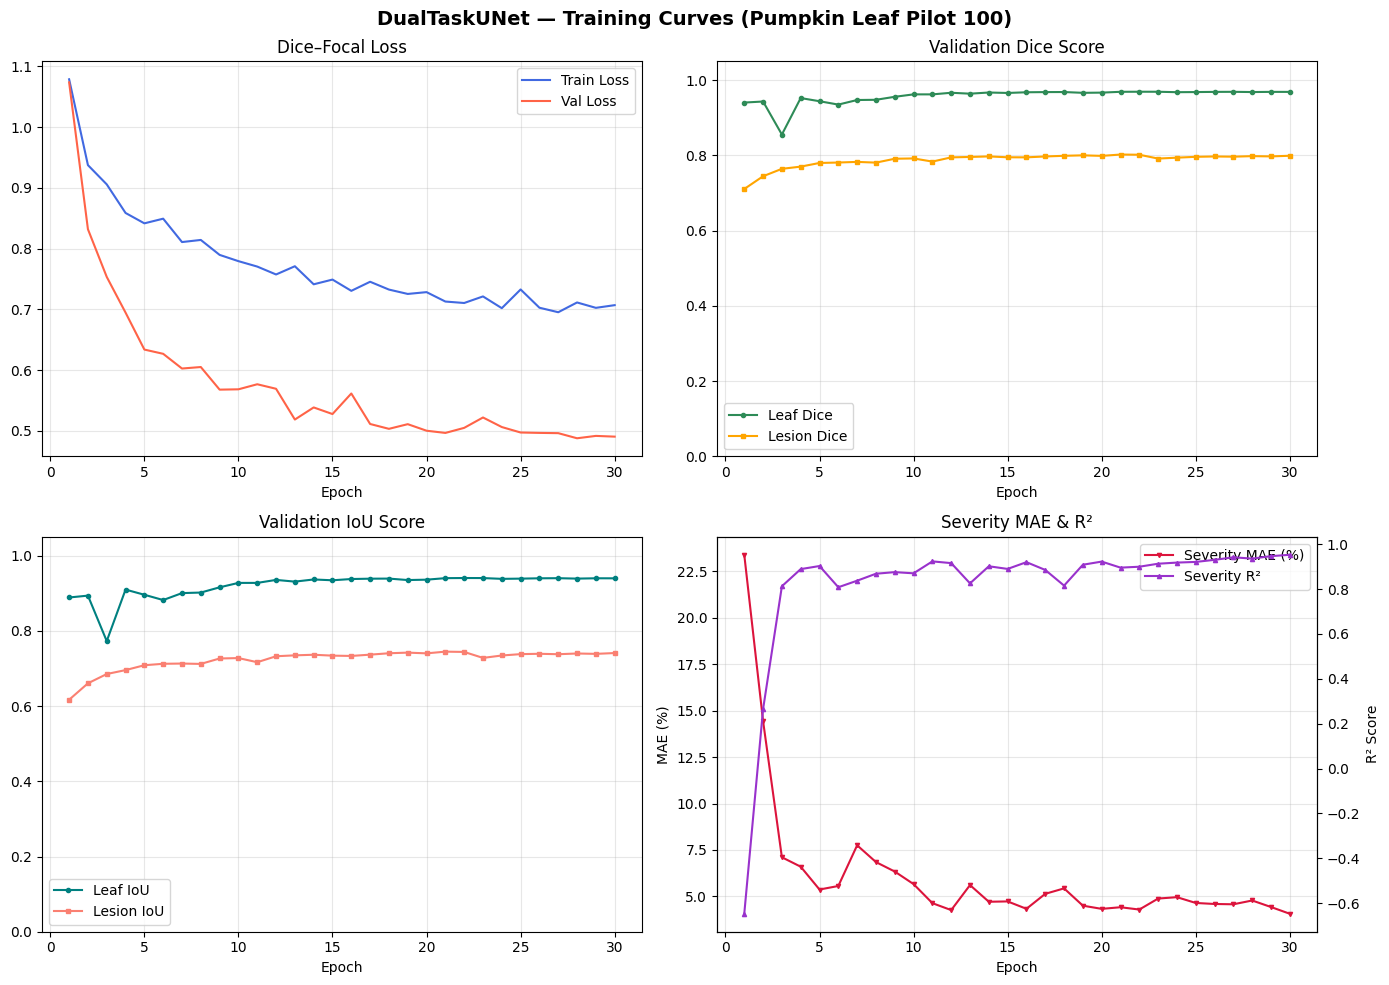

Training curves saved → /content/drive/MyDrive/pumpkin_severity_runs/dualtask_unet_run01/training_curves.png


In [10]:
# ==============================================================================
# CELL 7: TRAINING CURVES  (Loss · Dice · IoU · Severity MAE/R²)
# ==============================================================================
df_hist = pd.DataFrame(history)   # already in memory; reload if needed

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('DualTaskUNet — Training Curves (Pumpkin Leaf Pilot 100)', fontsize=14, fontweight='bold')

eps = df_hist['epoch']

# ── Loss ─────────────────────────────────────────────────────────────────────
ax = axes[0, 0]
ax.plot(eps, df_hist['train_loss'], label='Train Loss', color='royalblue')
ax.plot(eps, df_hist['val_loss'],   label='Val Loss',   color='tomato')
ax.set_title('Dice–Focal Loss'); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)

# ── Dice ─────────────────────────────────────────────────────────────────────
ax = axes[0, 1]
ax.plot(eps, df_hist['val_leaf_dice'], label='Leaf Dice',   color='seagreen', marker='o', ms=3)
ax.plot(eps, df_hist['val_les_dice'],  label='Lesion Dice', color='orange',   marker='s', ms=3)
ax.set_title('Validation Dice Score'); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)
ax.set_ylim(0, 1.05)

# ── IoU ──────────────────────────────────────────────────────────────────────
ax = axes[1, 0]
ax.plot(eps, df_hist['val_leaf_iou'], label='Leaf IoU',   color='teal',   marker='o', ms=3)
ax.plot(eps, df_hist['val_les_iou'],  label='Lesion IoU', color='salmon', marker='s', ms=3)
ax.set_title('Validation IoU Score'); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)
ax.set_ylim(0, 1.05)

# ── Severity ─────────────────────────────────────────────────────────────────
ax = axes[1, 1]
ax2 = ax.twinx()
ax.plot( eps, df_hist['sev_mae'], label='Severity MAE (%)', color='crimson',    marker='v', ms=3)
ax2.plot(eps, df_hist['sev_r2'],  label='Severity R²',      color='darkorchid', marker='^', ms=3)
ax.set_title('Severity MAE & R²'); ax.set_xlabel('Epoch')
ax.set_ylabel('MAE (%)'); ax2.set_ylabel('R² Score')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right'); ax.grid(alpha=0.3)

plt.tight_layout()
plot_path = os.path.join(RUN_DIR, 'training_curves.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Training curves saved → {plot_path}')


## Cell 8 — Test Set Evaluation (Best Checkpoint)

In [11]:
# ==============================================================================
# CELL 8: FINAL TEST EVALUATION  — loads best checkpoint, reports all metrics
# ==============================================================================
print('Loading best checkpoint...')
ckpt = torch.load(best_ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f"Best epoch: {ckpt['epoch']} | val_les_dice: {ckpt['val_les_dice']:.4f}")

model.eval()
test_leaf_dice, test_les_dice = [], []
test_leaf_iou,  test_les_iou  = [], []
test_pred_sevs, test_gt_sevs  = [], []
per_image_rows = []

with torch.no_grad():
    for imgs, masks, fnames, sevs_gt in test_dl:
        imgs  = imgs.to(device,  non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        logits= model(imgs)
        probs = torch.sigmoid(logits)
        pred_bin = (probs > THRESHOLD)
        gt_bin   = (masks > THRESHOLD)

        test_leaf_dice.append(dice_score(pred_bin[:,0], gt_bin[:,0]))
        test_les_dice.append( dice_score(pred_bin[:,1], gt_bin[:,1]))
        test_leaf_iou.append( iou_score( pred_bin[:,0], gt_bin[:,0]))
        test_les_iou.append(  iou_score( pred_bin[:,1], gt_bin[:,1]))

        ps = batch_severity(probs[:,0], probs[:,1], THRESHOLD)
        test_pred_sevs.extend(ps)
        test_gt_sevs.extend(sevs_gt.numpy().tolist())

        for fn, gts, prs in zip(fnames, sevs_gt.numpy().tolist(), ps):
            per_image_rows.append({'filename': fn, 'gt_severity_pct': round(gts,2),
                                   'pred_severity_pct': round(prs,2),
                                   'abs_error': round(abs(gts-prs),2)})

# ── Summary table ────────────────────────────────────────────────────────────
test_sev_mae = mean_absolute_error(test_gt_sevs, test_pred_sevs)
test_sev_r2  = r2_score(test_gt_sevs, test_pred_sevs) if len(set(test_gt_sevs)) > 1 else 0.0

print('\n' + '='*60)
print('  TEST SET EVALUATION — DualTaskUNet (Pilot 100)')
print('='*60)
print(f'  Leaf Mask    | Dice: {np.mean(test_leaf_dice):.4f}  | IoU: {np.mean(test_leaf_iou):.4f}')
print(f'  Lesion Mask  | Dice: {np.mean(test_les_dice):.4f}  | IoU: {np.mean(test_les_iou):.4f}')
print(f'  Severity     | MAE : {test_sev_mae:.2f}%  | R²  : {test_sev_r2:.4f}')
print('='*60)

# ── Per-image log ─────────────────────────────────────────────────────────────
df_per_img = pd.DataFrame(per_image_rows)
per_img_path = os.path.join(RUN_DIR, 'test_per_image_severity.csv')
df_per_img.to_csv(per_img_path, index=False)
print(f'Per-image severity CSV saved → {per_img_path}')
df_per_img

Loading best checkpoint...
Best epoch: 21 | val_les_dice: 0.8022

  TEST SET EVALUATION — DualTaskUNet (Pilot 100)
  Leaf Mask    | Dice: 0.9715  | IoU: 0.9453
  Lesion Mask  | Dice: 0.5506  | IoU: 0.4708
  Severity     | MAE : 3.89%  | R²  : 0.9376
Per-image severity CSV saved → /content/drive/MyDrive/pumpkin_severity_runs/dualtask_unet_run01/test_per_image_severity.csv


,filename,gt_severity_pct,pred_severity_pct,abs_error
0,HL_0057_Healthy Leaf (15).jpg,0.00,7.38,7.38
1,DM_0034_Downy Mildew (129).jpg,45.61,47.22,1.61
2,MD_0279_Mosaic Disease (35).jpg,80.18,82.97,2.79
3,MD_0267_Mosaic Disease (339).jpg,50.20,51.72,1.52
4,PM_0279_Powdery_Mildew (35).jpg,15.35,14.81,0.54
5,PM_0281_Powdery_Mildew (351).jpg,16.00,18.84,2.84
6,DM_0211_Downy Mildew (289).jpg,58.26,60.54,2.28
7,BLS_0210_Bacterial Leaf Spot (288).jpg,49.44,50.78,1.34
8,HL_0362_Healthy Leaf (64).jpg,0.00,17.96,17.96
9,BLS_0094_Bacterial Leaf Spot (183).jpg,21.28,20.69,0.59


## Cell 9 — Severity Scatter Plot (Ground Truth vs Predicted)

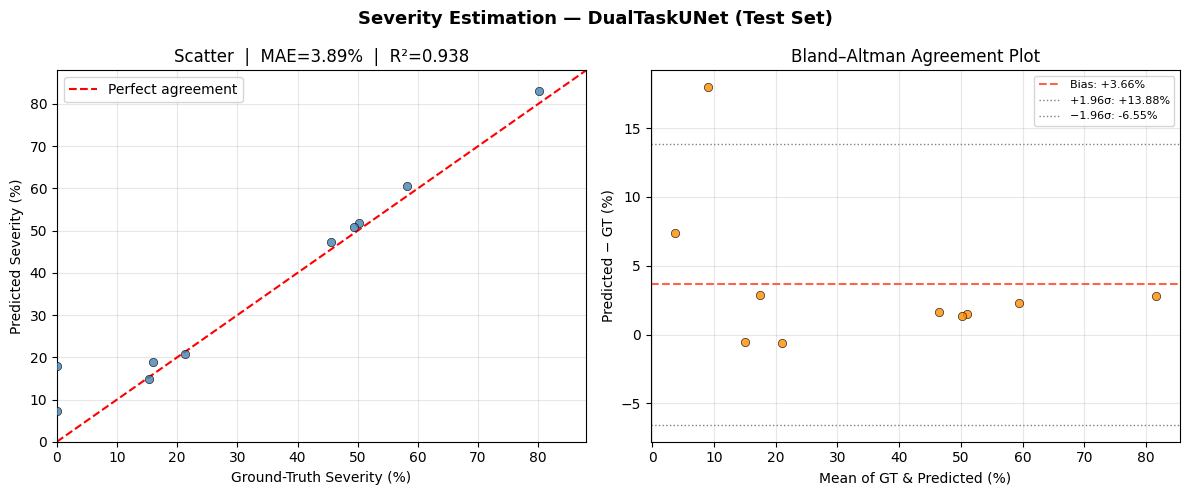

Severity scatter plot saved → /content/drive/MyDrive/pumpkin_severity_runs/dualtask_unet_run01/severity_scatter_blandaltman.png


In [12]:
# ==============================================================================
# CELL 9: GT vs PRED Severity Scatter  +  Bland-Altman agreement plot
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Severity Estimation — DualTaskUNet (Test Set)', fontsize=13, fontweight='bold')

gt  = np.array(test_gt_sevs)
pred= np.array(test_pred_sevs)

# ── Scatter: GT vs Predicted ─────────────────────────────────────────────────
ax = axes[0]
ax.scatter(gt, pred, alpha=0.8, edgecolors='k', linewidths=0.5, color='steelblue', zorder=3)
lim = max(gt.max(), pred.max()) + 5
ax.plot([0, lim], [0, lim], 'r--', lw=1.5, label='Perfect agreement')
ax.set_xlabel('Ground-Truth Severity (%)')
ax.set_ylabel('Predicted Severity (%)')
ax.set_title(f'Scatter  |  MAE={test_sev_mae:.2f}%  |  R²={test_sev_r2:.3f}')
ax.legend(); ax.grid(alpha=0.3); ax.set_xlim(0, lim); ax.set_ylim(0, lim)

# ── Bland-Altman Plot ─────────────────────────────────────────────────────────
ax = axes[1]
mean_vals = (gt + pred) / 2.0
diff_vals = pred - gt
bias  = diff_vals.mean()
limit = 1.96 * diff_vals.std()
ax.scatter(mean_vals, diff_vals, alpha=0.8, edgecolors='k', linewidths=0.5, color='darkorange', zorder=3)
ax.axhline(bias,         color='tomato',   ls='--', lw=1.5, label=f'Bias: {bias:+.2f}%')
ax.axhline(bias + limit, color='gray',     ls=':',  lw=1,   label=f'+1.96σ: {bias+limit:+.2f}%')
ax.axhline(bias - limit, color='gray',     ls=':',  lw=1,   label=f'−1.96σ: {bias-limit:+.2f}%')
ax.set_xlabel('Mean of GT & Predicted (%)')
ax.set_ylabel('Predicted − GT (%)')
ax.set_title('Bland–Altman Agreement Plot')
ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
scat_path = os.path.join(RUN_DIR, 'severity_scatter_blandaltman.png')
plt.savefig(scat_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Severity scatter plot saved → {scat_path}')


## Cell 10 — Visual Prediction Gallery (Test Set)

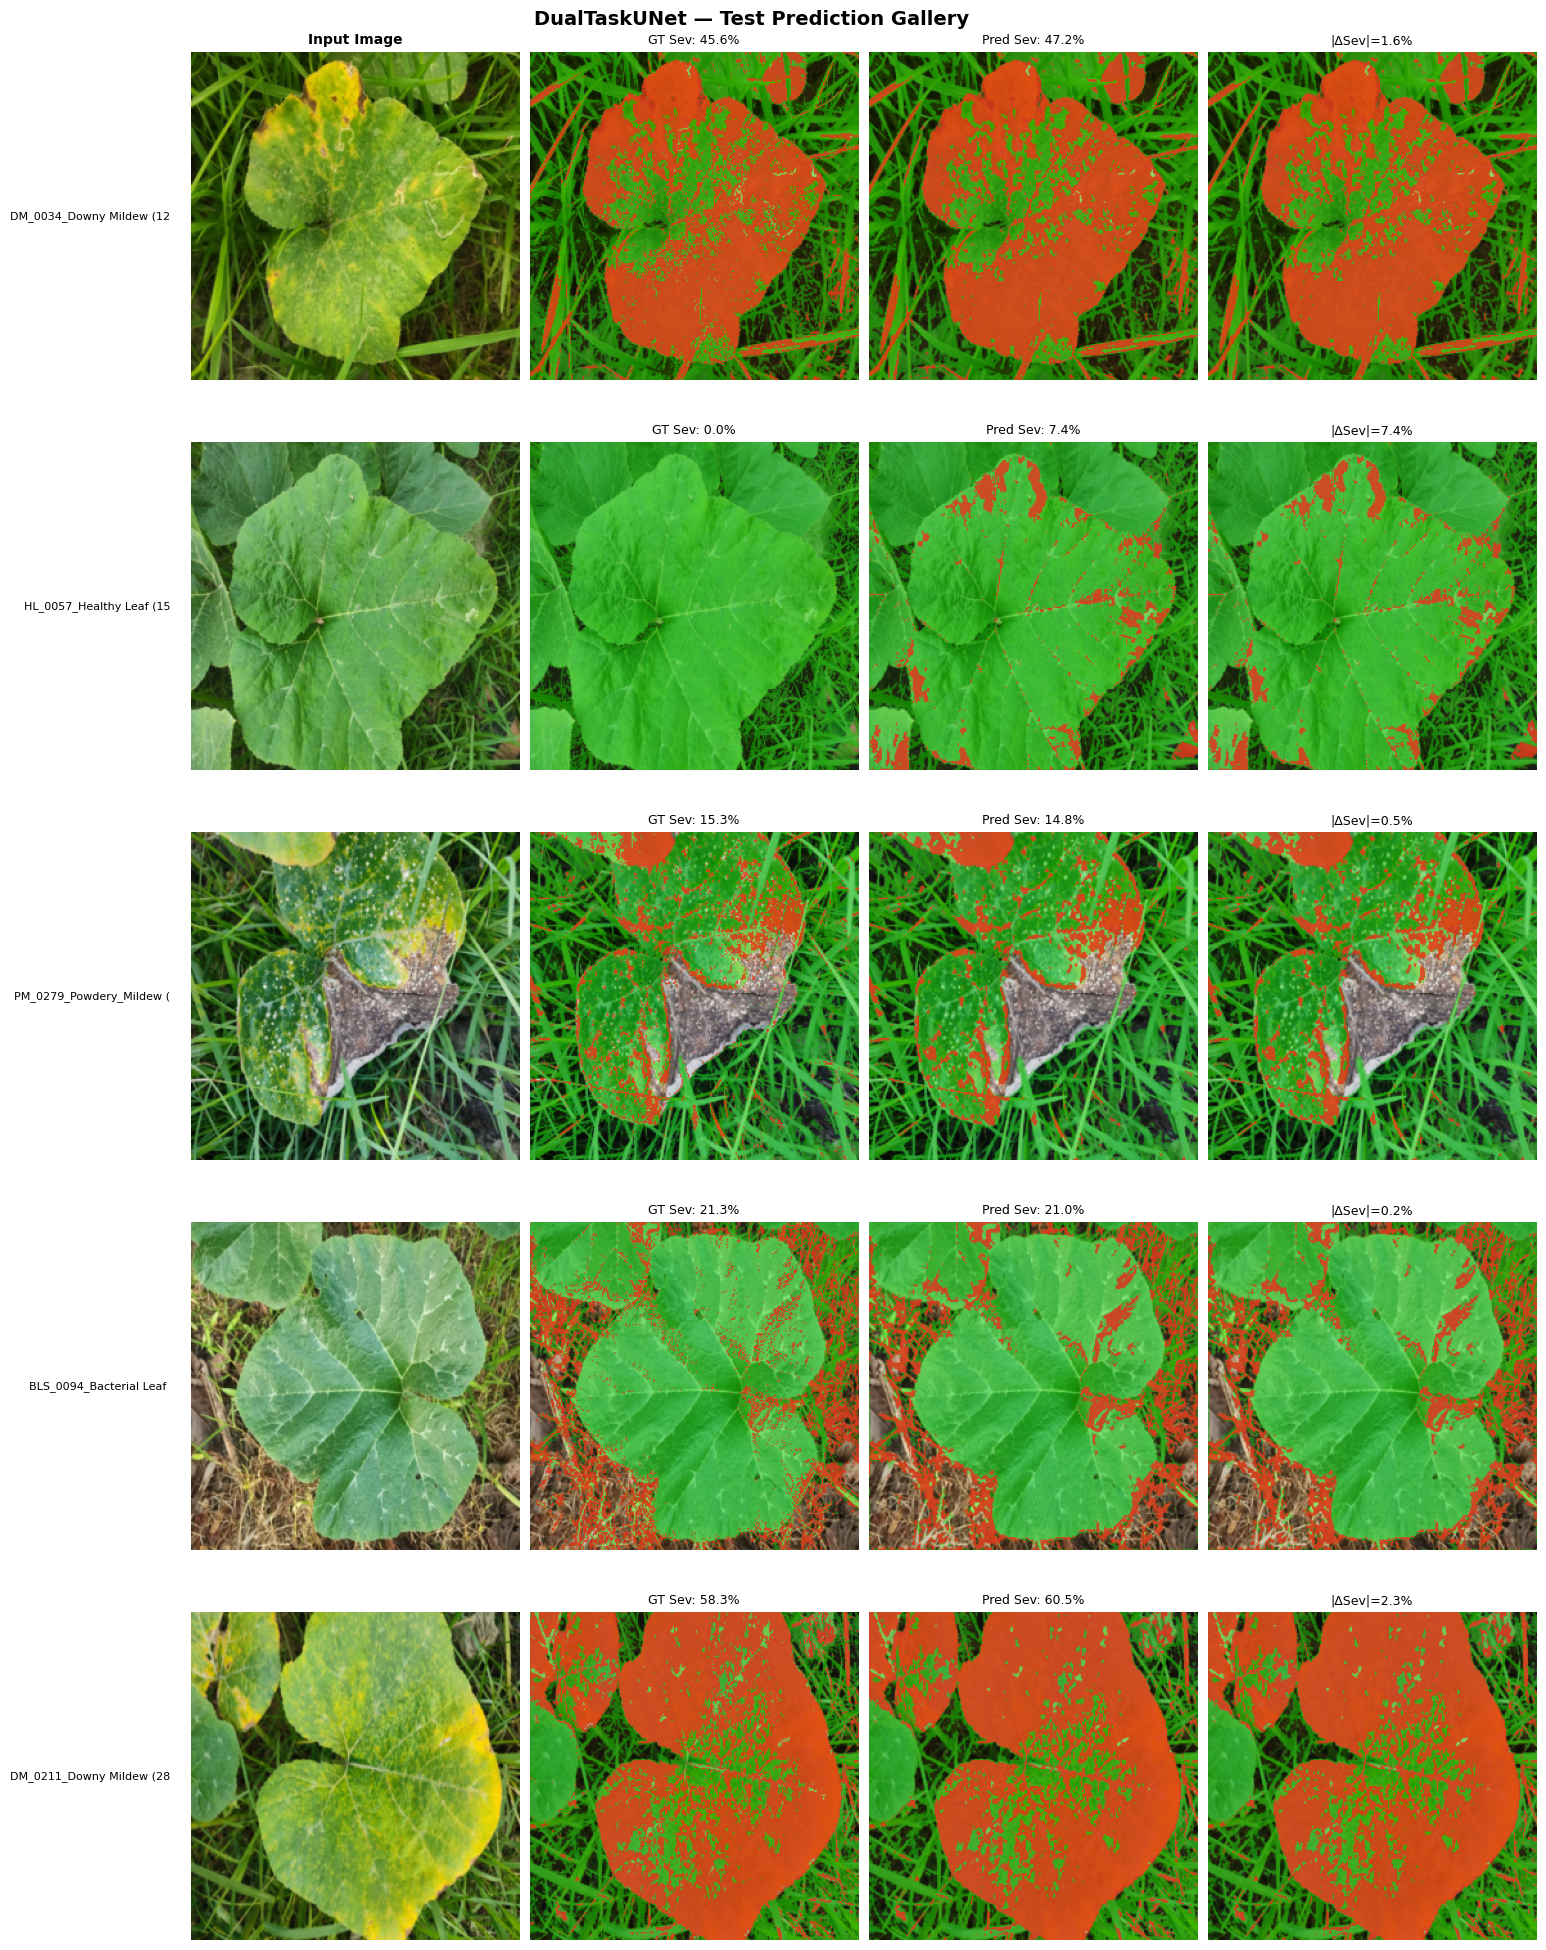

Prediction gallery saved → /content/drive/MyDrive/pumpkin_severity_runs/dualtask_unet_run01/prediction_gallery.png


In [13]:
# ==============================================================================
# CELL 10: VISUAL PREDICTION GALLERY — 5 test images × 4 panels
# ==============================================================================

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

def denorm(t):
    return torch.clamp(t * IMAGENET_STD + IMAGENET_MEAN, 0, 1)

model.eval()
n_show = min(5, len(test_ds))
indices = random.sample(range(len(test_ds)), n_show)

fig, axes = plt.subplots(n_show, 4, figsize=(16, 4*n_show))
if n_show == 1: axes = axes[np.newaxis, :]
fig.suptitle('DualTaskUNet — Test Prediction Gallery', fontsize=14, fontweight='bold')
col_titles = ['Input Image', 'GT Masks (leaf=G, lesion=R)', 'Pred Masks (leaf=G, lesion=R)', 'Severity Overlay']
for j, t in enumerate(col_titles):
    axes[0, j].set_title(t, fontsize=10, fontweight='bold')

with torch.no_grad():
    for row, idx in enumerate(indices):
        img_t, masks_t, fname, sev_gt = test_ds[idx]
        img_t_batch  = img_t.unsqueeze(0).to(device)
        logits       = model(img_t_batch)
        probs        = torch.sigmoid(logits)[0].cpu()   # [2, H, W]
        pred_bin     = (probs > THRESHOLD).numpy()
        gt_bin       = (masks_t > THRESHOLD).numpy()

        img_disp = denorm(img_t).permute(1,2,0).numpy()

        def make_overlay(img_np, leaf, lesion):
            o = img_np.copy()
            o[leaf]   = o[leaf]   * 0.6 + np.array([0, 0.8, 0]) * 0.4
            o[lesion & leaf] = o[lesion & leaf] * 0.3 + np.array([1.0, 0.1, 0.1]) * 0.7
            return np.clip(o, 0, 1)

        sev_pred_v = 100.0 * pred_bin[1].sum() / max(1, pred_bin[0].sum())

        axes[row, 0].imshow(img_disp)
        # Fixed filename label rotation and alignment to avoid layout collisions
        axes[row, 0].set_ylabel(fname[:24], fontsize=8, rotation=0, labelpad=15, va='center', ha='right')

        axes[row, 1].imshow(make_overlay(img_disp, gt_bin[0],   gt_bin[1]))
        axes[row, 1].set_title(f'GT Sev: {sev_gt:.1f}%', fontsize=9)

        axes[row, 2].imshow(make_overlay(img_disp, pred_bin[0], pred_bin[1]))
        axes[row, 2].set_title(f'Pred Sev: {sev_pred_v:.1f}%', fontsize=9)

        overlay = make_overlay(img_disp, pred_bin[0], pred_bin[1])
        axes[row, 3].imshow(overlay)
        axes[row, 3].set_title(f'|ΔSev|={abs(sev_gt-sev_pred_v):.1f}%', fontsize=9)

        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])
            # Keep only the left-hand y-axis label visible for filenames
            if ax != axes[row, 0]:
                ax.axis('off')
            else:
                ax.spines['top'].set_visible(False)
                ax.spines['right'].set_visible(False)
                ax.spines['bottom'].set_visible(False)
                ax.spines['left'].set_visible(False)

plt.tight_layout()
# Adjust subplots slightly to give extra space on the left margin for long filenames
fig.subplots_adjust(left=0.15)

gal_path = os.path.join(RUN_DIR, 'prediction_gallery.png')
plt.savefig(gal_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Prediction gallery saved → {gal_path}')

## Cell 11 — Log Results to `pumpkin_model_tracker.xlsx`

In [14]:
# ==============================================================================
# CELL 11: WRITE FINAL METRICS TO pumpkin_model_tracker.xlsx
# Adds a new row to the 'Run Log' sheet and updates the 'Comparison' sheet.
# ==============================================================================
import openpyxl
from datetime import datetime

TRACKER_PATH = '/content/drive/MyDrive/pumpkin_model_tracker.xlsx'   # adjust if stored elsewhere

new_row = {
    'Model': 'DualTaskUNet',
    'Architecture': 'U-Net (64→128→256→512→1024 enc-dec)',
    'Task': 'Segmentation + Severity',
    'Loss': 'DiceFocal(α=0.8 γ=2.0, lesion_w=2.5)',
    'Optimizer': 'AdamW(lr=3e-4, wd=1e-4)',
    'Scheduler': f'CosineAnnealing(T={EPOCHS})',
    'Input Size': f'{IMG_SIZE}x{IMG_SIZE}',
    'Batch Size': BATCH,
    'Epochs': EPOCHS,
    'Train/Val/Test Split': '80/10/10',
    'Leaf Dice (Test)': round(float(np.mean(test_leaf_dice)), 4),
    'Leaf IoU (Test)': round(float(np.mean(test_leaf_iou)), 4),
    'Lesion Dice (Test)': round(float(np.mean(test_les_dice)), 4),
    'Lesion IoU (Test)': round(float(np.mean(test_les_iou)), 4),
    'Severity MAE (%)': round(test_sev_mae, 2),
    'Severity R2': round(test_sev_r2, 4),
    'Dataset': 'Pilot 100 (automated masks)',
    'Notes': 'Baseline run — ExG+color threshold masks. Phase 6.',
    'Run Date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'Checkpoint': best_ckpt_path
}

try:
    wb = openpyxl.load_workbook(TRACKER_PATH)
except FileNotFoundError:
    wb = openpyxl.Workbook()

# ── Write to 'Run Log' sheet ──────────────────────────────────────────────────
if 'Run Log' not in wb.sheetnames:
    ws = wb.create_sheet('Run Log')
    ws.append(list(new_row.keys()))
else:
    ws = wb['Run Log']

ws.append(list(new_row.values()))
wb.save(TRACKER_PATH)
print(f'Run logged to {TRACKER_PATH} → Run Log sheet')

# ── Print final summary ───────────────────────────────────────────────────────
print('\n' + '='*60)
print('  FINAL RESULT SUMMARY')
print('='*60)
for k, v in new_row.items():
    print(f'  {k:<30s}: {v}')
print('='*60)


Run logged to /content/drive/MyDrive/pumpkin_model_tracker.xlsx → Run Log sheet

  FINAL RESULT SUMMARY
  Model                         : DualTaskUNet
  Architecture                  : U-Net (64→128→256→512→1024 enc-dec)
  Task                          : Segmentation + Severity
  Loss                          : DiceFocal(α=0.8 γ=2.0, lesion_w=2.5)
  Optimizer                     : AdamW(lr=3e-4, wd=1e-4)
  Scheduler                     : CosineAnnealing(T=30)
  Input Size                    : 256x256
  Batch Size                    : 8
  Epochs                        : 30
  Train/Val/Test Split          : 80/10/10
  Leaf Dice (Test)              : 0.9715
  Leaf IoU (Test)               : 0.9453
  Lesion Dice (Test)            : 0.5506
  Lesion IoU (Test)             : 0.4708
  Severity MAE (%)              : 3.89
  Severity R2                   : 0.9376
  Dataset                       : Pilot 100 (automated masks)
  Notes                         : Baseline run — ExG+color threshold mas